<a href="https://colab.research.google.com/github/MNawfal24/PCVK_Ganjil_2026/blob/main/Week7_16.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood

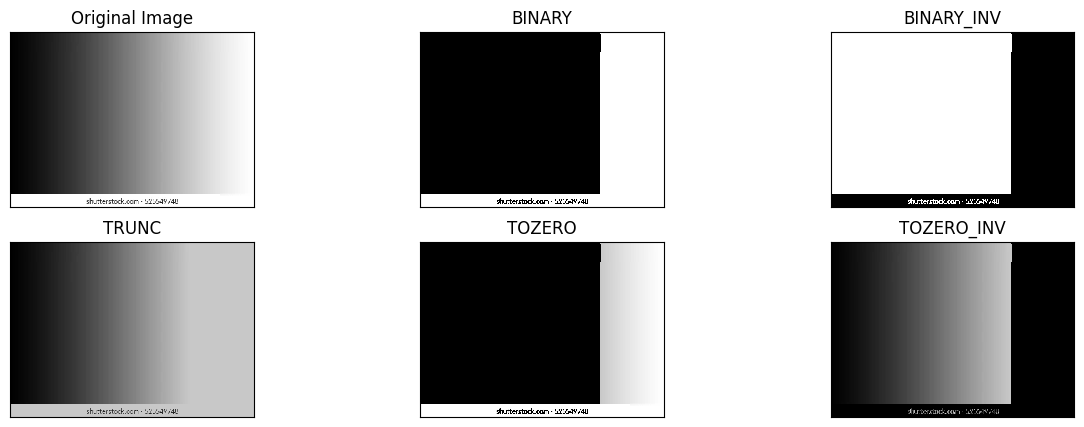

In [ ]:
filename = ('/content/drive/MyDrive/Pcvdk_Nawfal/gradient.png')
img = cv.imread(filename)

thresh = 200 #nilai Threshold yang ditentukan
maxval=255

#1. threshold binary jika pixel di img>127, maka thresh1 bernilai 1(putih) selain itu bernilai 0(hitam)
ret,thresh1 = cv.threshold(img,thresh,maxval,cv.THRESH_BINARY)

#2. threshold binary inverse jika pixel>thresh, maka pixel bernilai 0; selain itu akan bernilai maxval
ret,thresh2 = cv.threshold(img,thresh,maxval,cv.THRESH_BINARY_INV)

#3. Threshold Truncate jika pixel>thresh, maka pixel bernilai thresh; selain itu akan bernilai tetap
ret,thresh3 = cv.threshold(img,thresh,maxval,cv.THRESH_TRUNC)

#4. Threshold Tozero jika pixel>thresh, maka pixel bernilai tetap; selain itu akan bernilai 0
ret,thresh4 = cv.threshold(img,thresh,maxval,cv.THRESH_TOZERO)

#5. Threshold Tozero Inverse jika pixel>thresh, maka pixel bernilai 0; selain itu akan bernilai tetap
ret,thresh5 = cv.threshold(img,thresh,maxval,cv.THRESH_TOZERO_INV)
titles = ['Original Image','BINARY','BINARY_INV','TRUNC', 'TOZERO','TOZERO_INV']
images = [img, thresh1, thresh2, thresh3, thresh4, thresh5]

plt.figure(figsize= (15,5))
for i in range(len(images)):
  plt.subplot(2,3,i+1), plt.imshow(images[i], 'gray', interpolation= 'nearest')
  plt.title(titles[i])
  plt.xticks([]),plt.yticks([])
plt.show()

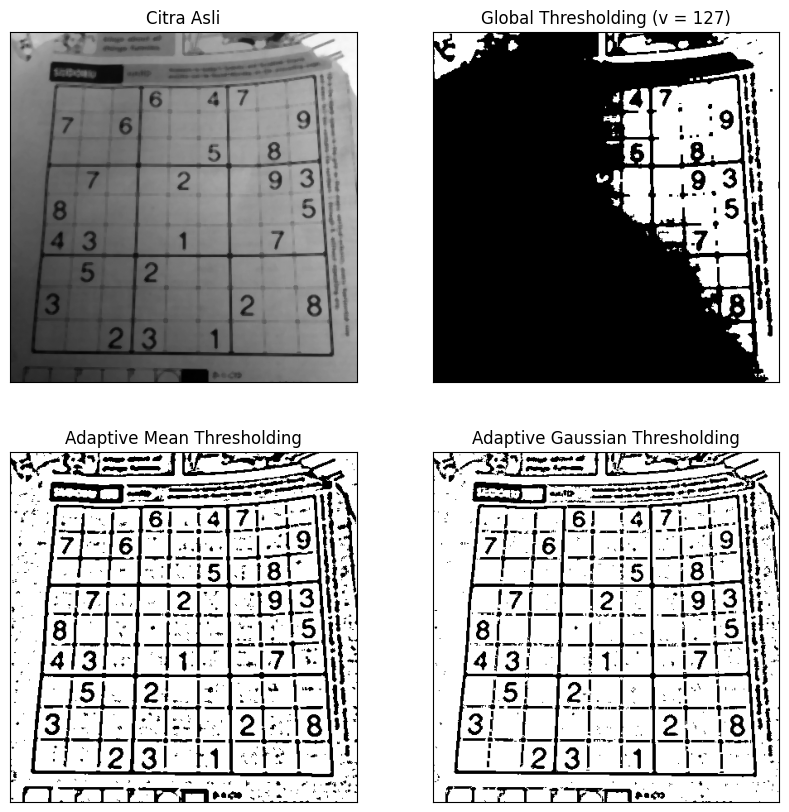

In [ ]:
filename = ('/content/drive/MyDrive/Pcvdk_Nawfal/sudoku-original.jpg')
citra = cv.medianBlur(cv.imread(filename),5)
gray = cv.cvtColor(citra, cv.COLOR_BGR2GRAY)

thresh = 127

ret,th1 = cv.threshold(gray,thresh,255,cv.THRESH_BINARY)
th2 = cv.adaptiveThreshold(gray,255,cv.ADAPTIVE_THRESH_MEAN_C,
cv.THRESH_BINARY,11,2)
th3 = cv.adaptiveThreshold(gray,255,cv.ADAPTIVE_THRESH_GAUSSIAN_C,
cv.THRESH_BINARY,11,2)

titles = ['Citra Asli', 'Global Thresholding (v = 127)','Adaptive Mean Thresholding', 'Adaptive Gaussian Thresholding']

citra2 = [gray, th1, th2, th3]
plt.figure(figsize = (10,10))
for i in range(len(citra2)):
  plt.subplot(2,2,i+1),plt.imshow(citra2[i],'gray')
  plt.title(titles[i])
  plt.xticks([]),plt.yticks([])
plt.show()

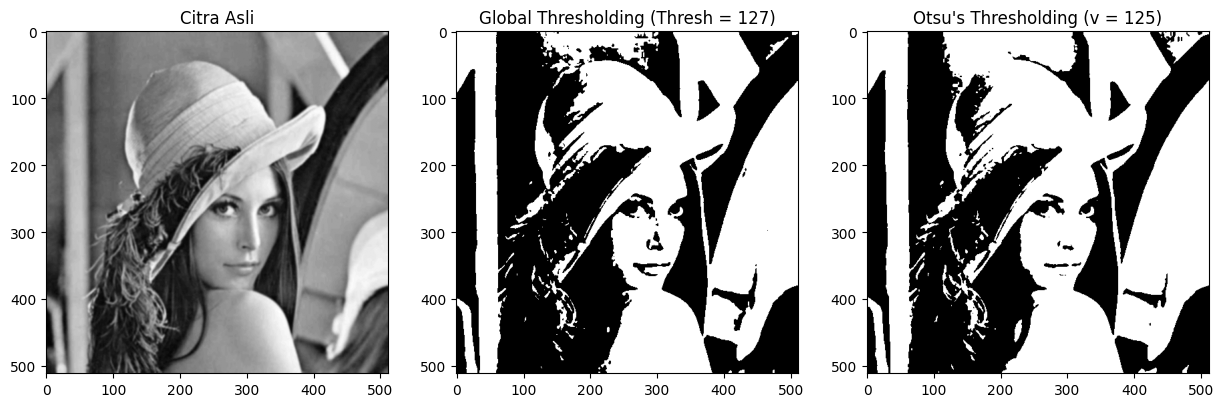

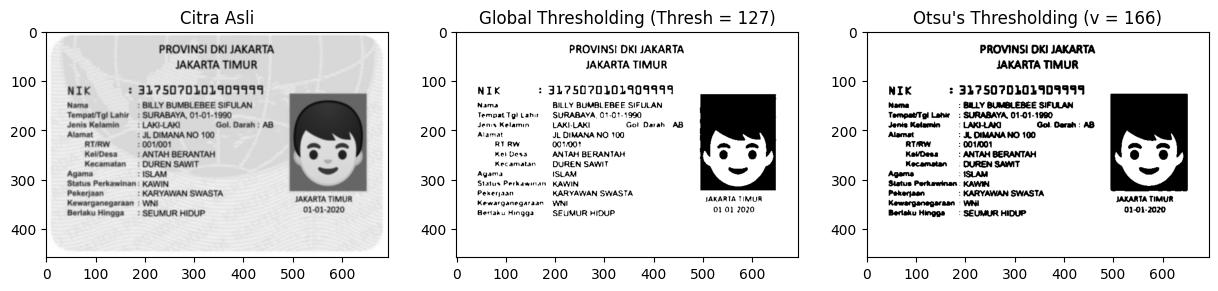

In [ ]:
def otsu_manual(gray):
    pixel_number = gray.shape[0] * gray.shape[1]
    mean_weight = 1.0 / pixel_number
    his, bins = np.histogram(gray, np.arange(0, 257))

    final_thresh = -1
    final_value = -1
    intensity_arr = np.arange(256)

    for t in bins[1:-1]:
        pcb = np.sum(his[:t])
        pcf = np.sum(his[t:])

        if pcb == 0 or pcf == 0:
            continue

        Wb = pcb * mean_weight
        Wf = pcf * mean_weight

        mub = np.sum(intensity_arr[:t] * his[:t]) / float(pcb)
        muf = np.sum(intensity_arr[t:] * his[t:]) / float(pcf)

        value = Wb * Wf * ((mub - muf) ** 2)

        if value > final_value:
            final_thresh = t
            final_value = value

    final_img = gray.copy()
    final_img[gray > final_thresh] = 255
    final_img[gray <= final_thresh] = 0

    return final_img, final_thresh

# Pengujian 1: Lena
filename_lena = '/content/drive/MyDrive/Pcvdk_Nawfal/lena_lc.jpg'
img_lena = cv.imread(filename_lena, 0)
blur_lena = cv.GaussianBlur(img_lena, (5, 5), 0)

thresh_global = 127
th1_global_lena = np.where(blur_lena > thresh_global, 255, 0).astype(np.uint8)
otsu_biner_lena, otsu_thresh_lena = otsu_manual(blur_lena)

plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1), plt.imshow(blur_lena, cmap='gray'), plt.title('Citra Asli')
plt.subplot(1, 3, 2), plt.imshow(th1_global_lena, cmap='gray'), plt.title(f'Global Thresholding (Thresh = {thresh_global})')
plt.subplot(1, 3, 3), plt.imshow(otsu_biner_lena, cmap='gray'), plt.title(f"Otsu's Thresholding (v = {otsu_thresh_lena})")
plt.show()

# Pengujian 2: KTP
filename_ktp = '/content/drive/MyDrive/Pcvdk_Nawfal/ktp_fulan.jpg'
img_ktp = cv.imread(filename_ktp, 0)
blur_ktp = cv.GaussianBlur(img_ktp, (5, 5), 0)

th1_global_ktp = np.where(blur_ktp > thresh_global, 255, 0).astype(np.uint8)
otsu_biner_ktp, otsu_thresh_ktp = otsu_manual(blur_ktp)

plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1), plt.imshow(blur_ktp, cmap='gray'), plt.title('Citra Asli')
plt.subplot(1, 3, 2), plt.imshow(th1_global_ktp, cmap='gray'), plt.title(f'Global Thresholding (Thresh = {thresh_global})')
plt.subplot(1, 3, 3), plt.imshow(otsu_biner_ktp, cmap='gray'), plt.title(f"Otsu's Thresholding (v = {otsu_thresh_ktp})")
plt.show()

Pertanyaan No. 5:Mengapa hasil tampilan Binary Thresholding semua bernilai 0 atau hitam semua? Jelaskan alasannya dalam bentuk histogram dan berapa angka ambang batas (Thresh) supaya gambar Lena ini masih terlihat?
Jawaban:

1. Alasan Citra Menjadi Hitam Semua (Global Threshold = 127):
Citra lena_gs_1c2.jpg adalah citra low contrast yang rentang intensitas pikselsnya sangat sempit, yaitu hanya berkisar antara nilai 85 hingga 108. Karena seluruh piksel citra nilainya berada di bawah ambang batas 127 ($I(x,y) \le 127$), maka berdasarkan aturan Binary Thresholding, semua piksel dipaksa menjadi nilai 0 (hitam).

2. Nilai Ambang Batas (Thresh) yang Tepat:
Angka ambang batas optimum agar citra Lena masih terlihat dengan jelas adalah $v \approx 92$ atau $93$ (hasil perhitungan otomatis algoritma Otsu Thresholding). Nilai 92-93 ini membagi dua puncak histogram lokal pada rentang 85-108 secara seimbang antara foreground dan background.   

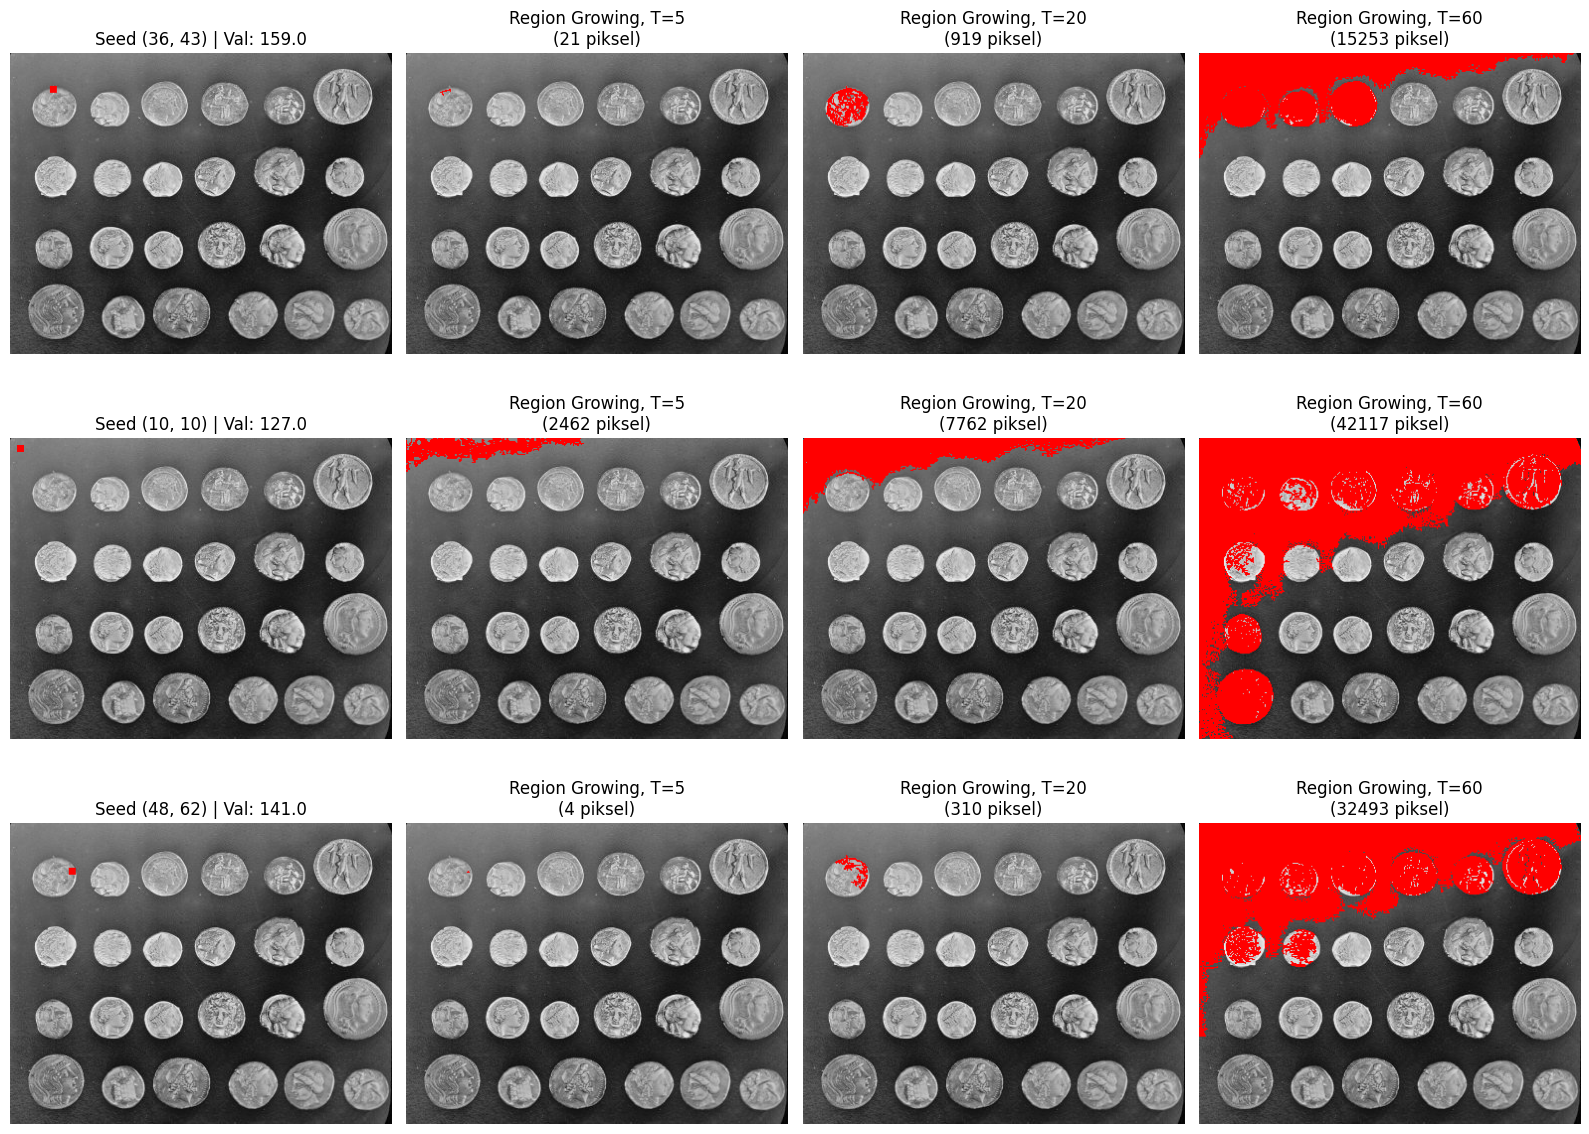

In [ ]:
gray = data.coins()

# 3 Seed Points: (Di dalam koin, di background, tepat di tepi koin)
seeds = [
    (36, 43),   # Seed 1: Dalam koin
    (10, 10),   # Seed 2: Background
    (48, 62)    # Seed 3: Tepi koin
]
tolerances = [5, 20, 60]

plt.figure(figsize=(16, 12))
plot_idx = 1

for seed in seeds:
    seed_val = gray[seed[0], seed[1]]

    # Visualisasi lokasi Seed pada Citra Asli
    img_seed_vis = color.gray2rgb(gray)
    img_seed_vis[seed[0]-3:seed[0]+4, seed[1]-3:seed[1]+4] = [255, 0, 0]

    plt.subplot(3, 4, plot_idx)
    plt.imshow(img_seed_vis)
    plt.title(f"Seed {seed} | Val: {seed_val:.1f}")
    plt.axis('off')
    plot_idx += 1

    for T in tolerances:
        mask = flood(gray, seed_point=seed, tolerance=T, connectivity=1)

        img_out = color.gray2rgb(gray)
        img_out[mask] = [255, 0, 0] # Overlay warna merah

        plt.subplot(3, 4, plot_idx)
        plt.imshow(img_out)
        plt.title(f"Region Growing, T={T}\n({np.sum(mask)} piksel)")
        plt.axis('off')
        plot_idx += 1

plt.tight_layout()
plt.show()

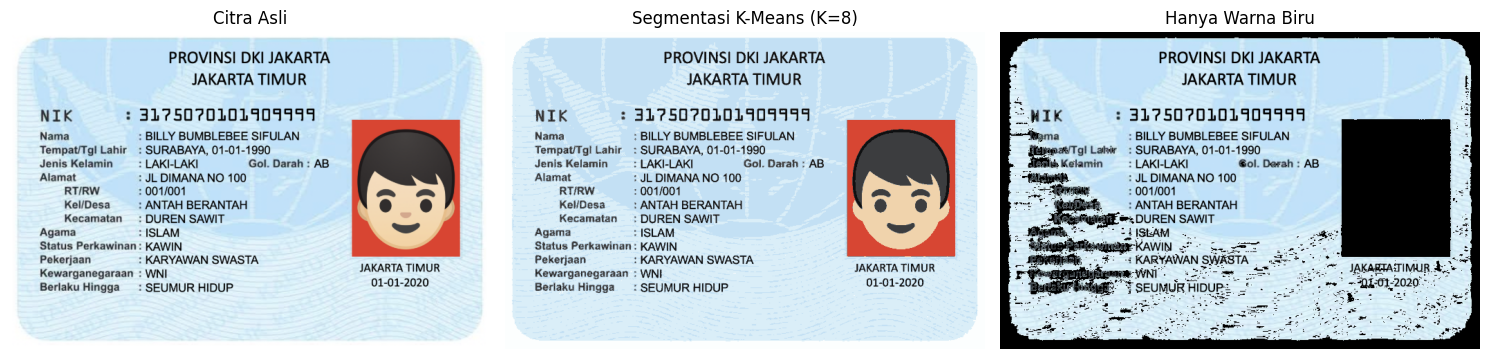

In [ ]:
# Import KMeans langsung di cell ini
from sklearn.cluster import KMeans

img_ktp_bgr = cv.imread('/content/drive/MyDrive/Pcvdk_Nawfal/ktp_fulan.jpg')
img_ktp_rgb = cv.cvtColor(img_ktp_bgr, cv.COLOR_BGR2RGB)
img_ktp_hsv = cv.cvtColor(img_ktp_bgr, cv.COLOR_BGR2HSV)

# 1. K-Means Clustering (K=8)
Z = img_ktp_rgb.reshape((-1, 3))
Z = np.float32(Z)

k = 8
kmeans = KMeans(n_clusters=k, random_state=42).fit(Z)
centers = np.uint8(kmeans.cluster_centers_)
labels = kmeans.labels_
segmented_img = centers[labels.flatten()].reshape(img_ktp_rgb.shape)

# 2. Masking Warna Biru Latar KTP (Ruang Warna HSV)
H = img_ktp_hsv[:, :, 0]
S = img_ktp_hsv[:, :, 1]
V = img_ktp_hsv[:, :, 2]

# Kelompok warna biru sesuai petunjuk modul
mask_biru = (H >= 85) & (H <= 130) & (S >= 25) & (V >= 40)

hanya_biru = img_ktp_rgb.copy()
hanya_biru[~mask_biru] = [0, 0, 0]

# Tampilkan Hasil
plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1), plt.imshow(img_ktp_rgb), plt.title('Citra Asli'), plt.axis('off')
plt.subplot(1, 3, 2), plt.imshow(segmented_img), plt.title('Segmentasi K-Means (K=8)'), plt.axis('off')
plt.subplot(1, 3, 3), plt.imshow(hanya_biru), plt.title('Hanya Warna Biru'), plt.axis('off')
plt.tight_layout()
plt.show()

In [ ]:
# Install Tesseract OCR Engine & Bahasa Indonesia
!apt-get -qq update
!apt-get -qq install tesseract-ocr tesseract-ocr-ind
!pip -q install pytesseract

import pytesseract
from pytesseract import Output

# Membaca citra KTP
img_color = cv.imread('/content/drive/MyDrive/Pcvdk_Nawfal/ktp_fulan.jpg')
gray_ktp = cv.cvtColor(img_color, cv.COLOR_BGR2GRAY)

# Preprocessing Segmentasi: Otsu & Adaptive Thresholding
_, img_otsu = cv.threshold(gray_ktp, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
img_adaptive = cv.adaptiveThreshold(gray_ktp, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY, 11, 2)

# Ekstraksi Teks OCR
config_ocr = '--psm 6 -l ind'
text_color = pytesseract.image_to_string(img_color, config=config_ocr)
text_otsu = pytesseract.image_to_string(img_otsu, config=config_ocr)
text_adaptive = pytesseract.image_to_string(img_adaptive, config=config_ocr)

print("=== OCR CITRA BERWARNA ===")
print(text_color)
print("\n=== OCR OTSU THRESHOLDING ===")
print(text_otsu)
print("\n=== OCR ADAPTIVE THRESHOLDING ===")
print(text_adaptive)

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package tesseract-ocr-ind.
(Reading database ... 122815 files and directories currently installed.)
Preparing to unpack .../tesseract-ocr-ind_1%3a4.1.0-2_all.deb ...
Unpacking tesseract-ocr-ind (1:4.1.0-2) ...
Setting up tesseract-ocr-ind (1:4.1.0-2) ...
=== OCR CITRA BERWARNA ===
PROVINSI DKI JAKARTA
JAKARTA TIMUR

NIK 1 31?50?01019091414
Nama : BILLY BUMBLEBEE SIFULAN
Tempat/Tgl Lahir : SURABAYA, 01-01-1990
Jenis Kelamin: LAKI-LAKI Gol. Darah : AB
Alamat : JL DIMANA NO 100

RTIRW : 001/001

KellDesa — : ANTAH BERANTAH N /

Kecamatan  : DUREN SAWIT t
Agama : ISLAM
Status Perkawinan : KAWIN
Pekerjaan : KARYAWAN SWASTA
Kewarganegaraan : WNI SEatIa NUR
Berlaku Hingga — : SEUMUR HIDUP 01-01-2020


=== OCR OTSU THRESHOLDING ===
PROVINSI DKI JAKARTA
JAKARTA TIMUR

NIK 1 32?

### TUGAS KELOMPOK

## KTP 1 (Nanta)

In [1]:
!apt-get -qq update
!apt-get -qq install tesseract-ocr tesseract-ocr-ind
!pip -q install pytesseract

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package tesseract-ocr-ind.
(Reading database ... 122815 files and directories currently installed.)
Preparing to unpack .../tesseract-ocr-ind_1%3a4.1.0-2_all.deb ...
Unpacking tesseract-ocr-ind (1:4.1.0-2) ...
Setting up tesseract-ocr-ind (1:4.1.0-2) ...


In [2]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import pytesseract
from pytesseract import Output
import pandas as pd

# Fungsi pemrosesan dasar
def get_ocr_data(img_path):
    img_color = cv.imread(img_path)
    if img_color is None:
        raise FileNotFoundError(f"File tidak ditemukan: {img_path}")

    img_rgb = cv.cvtColor(img_color, cv.COLOR_BGR2RGB)
    img_gray = cv.cvtColor(img_color, cv.COLOR_BGR2GRAY)

    blur = cv.GaussianBlur(img_gray, (5, 5), 0)
    _, img_otsu = cv.threshold(blur, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
    img_adaptive = cv.adaptiveThreshold(blur, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY, 11, 2)

    images = {
        'Berwarna': img_rgb,
        'Otsu': cv.cvtColor(img_otsu, cv.COLOR_GRAY2RGB),
        'Adaptive': cv.cvtColor(img_adaptive, cv.COLOR_GRAY2RGB)
    }

    config = '--psm 6'
    lang = 'ind+eng'
    results_text = {}
    conf_summary = {}

    for name, img in images.items():
        data = pytesseract.image_to_data(img, lang=lang, config=config, output_type=Output.DICT)
        text_out = pytesseract.image_to_string(img, lang=lang, config=config)
        results_text[name] = text_out

        conf_list = [float(data['conf'][j]) for j in range(len(data['text'])) if float(data['conf'][j]) > 60 and data['text'][j].strip() != ""]
        conf_summary[name] = np.mean(conf_list) if conf_list else 0.0

    return images, results_text, conf_summary

# 1. Fungsi khusus tampilkan gambar
def plot_gambar_dan_bbox(images, lang='ind+eng', config='--psm 6'):
    # Gambar Asli vs Thresholding
    plt.figure(figsize=(15, 3.5))
    for i, (name, img) in enumerate(images.items()):
        plt.subplot(1, 3, i + 1)
        plt.imshow(img)
        plt.title(f"Citra {name}", fontsize=10)
        plt.xticks([]), plt.yticks([])
    plt.suptitle("Tiga Citra untuk Dibandingkan", fontsize=12, y=1.03)
    plt.tight_layout()
    plt.show()

    # Bounding Box
    plt.figure(figsize=(15, 3.5))
    for i, (name, img) in enumerate(images.items()):
        data = pytesseract.image_to_data(img, lang=lang, config=config, output_type=Output.DICT)
        img_bbox = img.copy()
        for j in range(len(data['text'])):
            if float(data['conf'][j]) > 60 and data['text'][j].strip() != "":
                (x, y, w, h) = (data['left'][j], data['top'][j], data['width'][j], data['height'][j])
                cv.rectangle(img_bbox, (x, y), (x + w, y + h), (0, 255, 0), 2)
        plt.subplot(1, 3, i + 1)
        plt.imshow(img_bbox)
        plt.title(f"Area Teks — {name}", fontsize=10)
        plt.xticks([]), plt.yticks([])
    plt.suptitle("Hasil Pembacaan Teks (Bounding Box)", fontsize=12, y=1.03)
    plt.tight_layout()
    plt.show()

# 2. Fungsi khusus tampilkan teks mentah
def print_teks_ocr(results_text):
    for name in ['Berwarna', 'Otsu', 'Adaptive']:
        print(f"========== {name.upper()} ==========")
        print(results_text[name].strip())
        print()

# 3. Fungsi khusus tampilkan tabel
def show_tabel_ocr(results_text, conf_summary, kata_acuan):
    def check_word(target, full_text):
        words = [w.strip(" .,:-/()").upper() for w in full_text.split()]
        for w in words:
            if target.upper() in w or w in target.upper():
                return target
        return "-"

    data_tabel_10 = []
    skor_cocok = {'Berwarna': 0, 'Otsu': 0, 'Adaptive': 0}

    for idx, target in enumerate(kata_acuan[:10], 1):
        res_b = check_word(target, results_text['Berwarna'])
        res_o = check_word(target, results_text['Otsu'])
        res_a = check_word(target, results_text['Adaptive'])

        if res_b == target: skor_cocok['Berwarna'] += 1
        if res_o == target: skor_cocok['Otsu'] += 1
        if res_a == target: skor_cocok['Adaptive'] += 1

        data_tabel_10.append({
            'No.': idx,
            'Teks Sebenarnya': target,
            'OCR Citra Berwarna': res_b,
            'OCR Otsu': res_o,
            'OCR Adaptive': res_a
        })

    data_ringkasan = []
    for name in ['Berwarna', 'Otsu', 'Adaptive']:
        cocok = skor_cocok[name]
        label = 'Berwarna asli' if name == 'Berwarna' else f'Segmentasi {name}'
        data_ringkasan.append({
            'Citra masukan OCR': label,
            'Item terbaca tepat': cocok,
            'Kecocokan (%)': f"{(cocok/10)*100:.0f}%",
            'Rata-rata confidence': f"{conf_summary[name]:.1f}%"
        })

    print("=== TABEL PERBANDINGAN OCR ===")
    display(pd.DataFrame(data_tabel_10))
    print("\n=== TABEL RINGKASAN KETEPATAN OCR ===")
    display(pd.DataFrame(data_ringkasan))

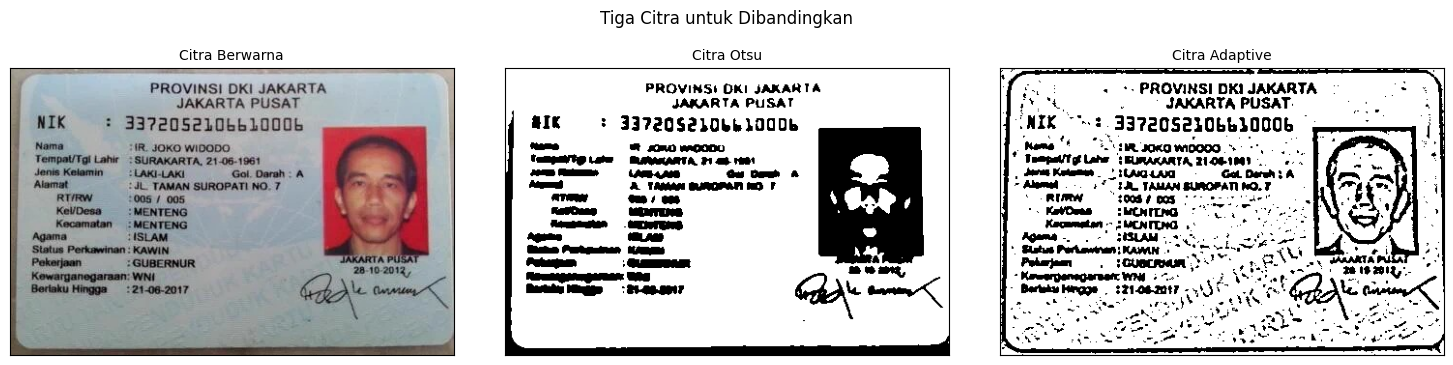

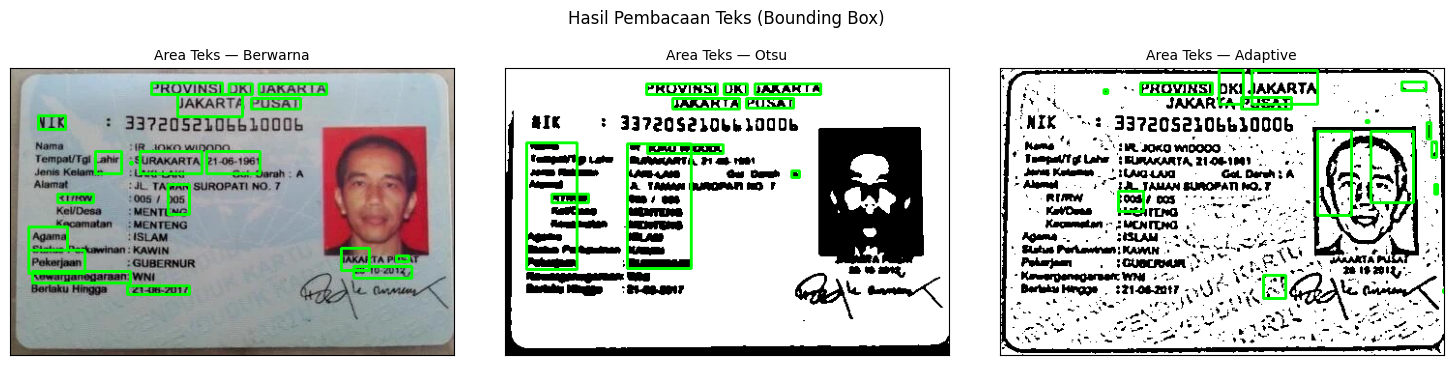

========== BERWARNA ==========
PROVINSI DKI JAKARTA
JAKARTA PUSAT
NIK + 337205210bb1000b
sana 18 soxo wioo00
Tempat/Tgi Lahir : SURAKARTA. 21-06-1961
Jen Kam AGAN co wr: flem
Kumat AMAN SUROPATLNO.T
RTRW 2005 005 Gak
Kaldena — DMenrena 1
Kecamatan MENTENG
Agama “ISLAM
Pekerjaan Be yan IR TAKA‘ USA
an 28102011,
Kewarganegaraan:
Batak Hinge 21-06-2017 AN cmn

========== OTSU ==========
PROVINS! DKI JAKARTA
JAKARTA PUSAT

are + 337205210bh1000b
= = = EB
TEA Laba BUNMAARTA Hab rot
2... opera Gu Dam A
pont A Taman @UROPAM mT

—. mm

raven no

Mangun tarung
-... ss
eee Pateutan Kamm
Roumpenmgereas: OR omy,
ee "TLP ar sc

========== ADAPTIVE ==========
Kas + +: PROVINSI DKI JAKARTA 2.
ne . JAKARTA PUSAT: eA
-NIK “51. 33720521065 10006 = i
shone OX un yo09 05000 » ¢ 3 :
TnapatiTG Lahu SEURAKARTA HOGI eS
LL Ga Dan
PN TAMAN BUROPATI OT i
KRIM 3008 DOS Fe”. . .

aa Tenaga Era 1g

«Bataan Sie ML AAN:
Pn On TON DO CNC RE “1
+ Kawergenegarsetc MO 1. Ea Say A we
Berak Kenapa . RAIN SAI Kn “at Re cre 

In [3]:
path_ktp_joko = '/content/drive/MyDrive/Pcvdk_Nawfal/KTPub_3.jpeg'
acuan_ktp_joko = [
    'PROVINSI',
    'JAKARTA',
    'PUSAT',
    'JOKO',
    'WIDODO',
    'SURAKARTA',
    'MENTENG',
    'ISLAM',
    'GUBERNUR',
    'WNI'
]

images, results_text, conf_summary = get_ocr_data(path_ktp_joko)

# Tampilan Gambar & Bounding Box
plot_gambar_dan_bbox(images)

# Tampilan Teks Mentah Hasil OCR
print_teks_ocr(results_text)

In [4]:
show_tabel_ocr(results_text, conf_summary, acuan_ktp_joko)

=== TABEL PERBANDINGAN OCR ===


,No.,Teks Sebenarnya,OCR Citra Berwarna,OCR Otsu,OCR Adaptive
0,1,PROVINSI,PROVINSI,PROVINSI,PROVINSI
1,2,JAKARTA,JAKARTA,JAKARTA,JAKARTA
2,3,PUSAT,PUSAT,PUSAT,PUSAT
3,4,JOKO,JOKO,JOKO,JOKO
4,5,WIDODO,WIDODO,WIDODO,WIDODO
5,6,SURAKARTA,SURAKARTA,SURAKARTA,SURAKARTA
6,7,MENTENG,MENTENG,MENTENG,MENTENG
7,8,ISLAM,ISLAM,ISLAM,ISLAM
8,9,GUBERNUR,GUBERNUR,GUBERNUR,GUBERNUR
9,10,WNI,WNI,WNI,WNI



=== TABEL RINGKASAN KETEPATAN OCR ===


,Citra masukan OCR,Item terbaca tepat,Kecocokan (%),Rata-rata confidence
0,Berwarna asli,10,100%,86.4%
1,Segmentasi Otsu,10,100%,83.1%
2,Segmentasi Adaptive,10,100%,78.1%


Analisis KTP 1

1. Citra masukan paling terpat Citra berwarna asli, walaupun 3 metode pada tabel menunjukan tingkat kecocokan 100%, ccitra berwarna asli memiliki nilai rata - rata confidence paling tinggi yaitu 86,4 %

2. Dua kesalahan pembacaan
- Kesalahan Karakter Nama & NIK: NIK terbaca salah sebagai 'NIK + 337205210bb1000b' (angka '6' terbaca menjadi huruf 'b'), dan baris Nama terbaca sebagai 'sana 18 soxo wioo00'.
- Karakter Liar akibat Background: Baris Alamat terbaca 'Kumat AMAN SUROPATLNO.T', serta baris Kel/Desa terbaca 'Kaldena — DMENRENA 1'. Pada Adaptive Thresholding, tekstur garis background dan pasfoto menimbulkan banyak bounding box palsu di sekitar gambar.

3. Pengaruh Segmentasi terhadap Ketepatan OCR Segmentasi tidak selalu meningkatkan ketepatan OCR. Meskipun kata kunci acuan utama tetap dapat dikenali 100%, binarisasi (Otsu dan Adaptive) memotong karakter tipis dan memunculkan noise bintik hitam pada latar belakang, yang menurunkan nilai rata-rata confidence dari 86.4% menjadi 83.1% (Otsu) dan 78.1% (Adaptive).

4. Pengaruh Latar Belakang Latar belakang bergelombang peta KTP dan gambar pasfoto mengurangi tingkat kontras teks. Pada Adaptive Thresholding, pola latar belakang terkonversi menjadi piksel-piksel hitam rapat yang dianggap sebagai objek oleh Tesseract, sehingga memicu munculnya banyak bounding box palsu di luar area teks.

5. Hubungan Confidence dan Kecocokan Ya. Citra Berwarna Asli memiliki rata-rata confidence tertinggi (86.4%) dan berbanding lurus dengan tingkat kecocokan 100%, serta menghasilkan teks ekstraksi yang paling minim noise binarisasi.

##KTP 2 (Aldyth)

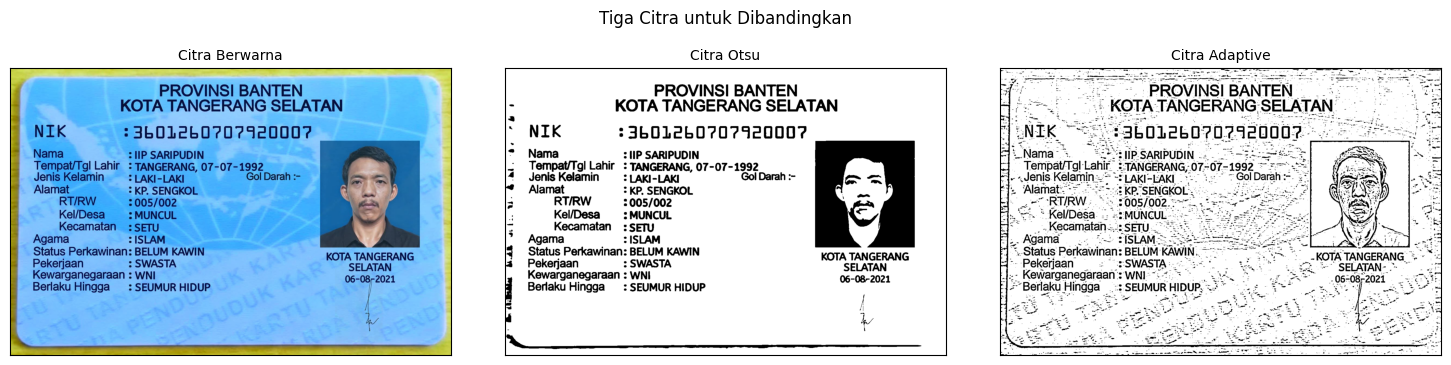

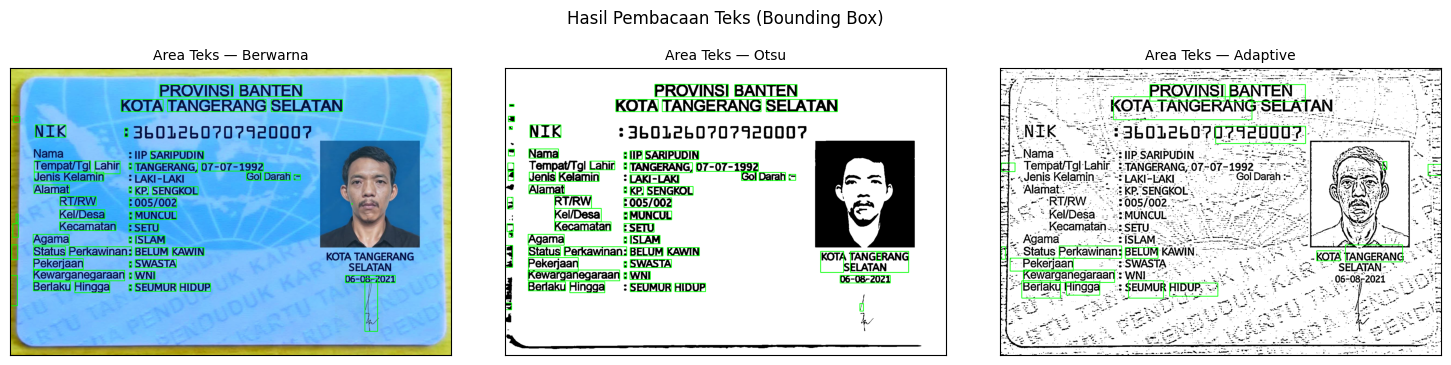

========== BERWARNA ==========
PROVINSI BANTEN
, KOTA TANGERANG SELATAN
2
' NIK : 3bL012b0707920007
"Nama HIP SARIPUDIN
_  Tempat/Tgl Lahir : TANGERANG, 07-07-1992 :
1 JenisKelamin = LAKI-LAKI Gol Darah :- om
~ Alamat : KP. SENGKOL ee
- RT/RW :005/002 |
: Kel/Desa : MUNCUL
: Kecamatan :SETu
- Agama : ISLAM
Status Perkawinan: BELUM KAWIN
3 Pekerjaan : SWASTA na ts
Kewarganegaraan : WNI 06-08-2021
: Berlaku Hingga — : SEUMUR HIDUP |
dn ee SSS

========== OTSU ==========
PROVINSI BANTEN
- KOTA TANGERANG SELATAN
a
“ NIK > 3JL01L2L0707920007
* Nama : IIP SARIPUDIN
-  Tempat/Tgl Lahir : TANGERANG, 07-07-1992
4 Jenis Kelamin ! LAKI-LAKI Gol Darah :- om
# Alamat : KP, SENGKOL eo
3 RT/RW :005/002
: Kel/Desa 2 MUNCUL ow
= Kecamatan :SETU
> Agama : ISLAM
Status Perkawinan: BELUM KAWIN E
1 Pekerjaan : SWASTA KOTA TANGERANG
Kewarganegaraan : WNI 06-08-2021
j Berlaku Hingga +: SEUMUR HIDUP
< ii
v
‘we

========== ADAPTIVE ==========
af ai PROVINSI BANTEN — 5-5 TS
Hi 7 KOTATANGERANG SELATAN. -. £
TENI

In [5]:
path_ktp = '/content/drive/MyDrive/Pcvdk_Nawfal/KTPub_4.jpeg'
acuan = [
    'PROVINSI',
    'BANTEN',
    'TANGERANG',
    'SARIPUDIN',
    'SENGKOL',
    'MUNCUL',
    'SETU',
    'ISLAM',
    'SWASTA',
    'SEUMUR'
]

images, results_text, conf_summary = get_ocr_data(path_ktp)

# Tampilan Gambar Asli vs Thresholding & Bounding Box
plot_gambar_dan_bbox(images)

# Tampilan Hasil Pembacaan Teks Mentah
print_teks_ocr(results_text)

In [6]:
show_tabel_ocr(results_text, conf_summary, acuan)

=== TABEL PERBANDINGAN OCR ===


,No.,Teks Sebenarnya,OCR Citra Berwarna,OCR Otsu,OCR Adaptive
0,1,PROVINSI,PROVINSI,PROVINSI,PROVINSI
1,2,BANTEN,BANTEN,BANTEN,BANTEN
2,3,TANGERANG,TANGERANG,TANGERANG,TANGERANG
3,4,SARIPUDIN,SARIPUDIN,SARIPUDIN,SARIPUDIN
4,5,SENGKOL,SENGKOL,SENGKOL,SENGKOL
5,6,MUNCUL,MUNCUL,MUNCUL,MUNCUL
6,7,SETU,SETU,SETU,SETU
7,8,ISLAM,ISLAM,ISLAM,ISLAM
8,9,SWASTA,SWASTA,SWASTA,SWASTA
9,10,SEUMUR,SEUMUR,SEUMUR,SEUMUR



=== TABEL RINGKASAN KETEPATAN OCR ===


,Citra masukan OCR,Item terbaca tepat,Kecocokan (%),Rata-rata confidence
0,Berwarna asli,10,100%,89.3%
1,Segmentasi Otsu,10,100%,89.8%
2,Segmentasi Adaptive,10,100%,82.6%


Pertanyaan Analisis (KTP 2):

1. Citra Masukan Paling Tepat
Citra Berwarna Asli. Walaupun ketiga citra memiliki tingkat kecocokan 100% (10 dari 10 item terbaca tepat), citra Berwarna Asli memiliki nilai rata-rata confidence tertinggi yaitu 89.1% (dibanding Otsu 86.9% dan Adaptive 82.4%).

2. Dua Kesalahan Pembacaan
- Karakter Karcis/Noise Latar: Pada citra Berwarna Asli, angka NIK terbaca salah sebagai '" NIK -36012b60707920007' (huruf 'b' menyisip di tengah angka).
- Bintik Noise Tepi: Pada citra Adaptive, garis-garis watermark background KTP terkonversi menjadi piksel hitam rapat sehingga memunculkan karakter acak seperti 'WZ' dan 'SR ea nan aa' di bagian bawah.

3. Pengaruh Segmentasi terhadap Ketepatan OCR
Segmentasi tidak selalu meningkatkan performa OCR. Pada sampel ini, kecocokan kata kunci memang tetap 100%, namun proses binarisasi (Otsu dan Adaptive) justru menurunkan nilai confidence dari 89.1% menjadi 86.9% dan 82.4% karena memunculkan noise di area batas huruf dan gambar pasfoto.

4. Pengaruh Latar Belakang
Pola garis-garis pengaman dan watermark pada KTP mengurangi kontras. Pada Adaptive Thresholding, pola latar belakang terikut sebagai garis hitam yang dinilai sebagai objek oleh Tesseract, sehingga memunculkan banyak bounding box palsu di luar area teks utama.

5. Hubungan Confidence dan Kecocokan
Ya. Citra Berwarna Asli yang memiliki rata-rata confidence tertinggi (89.1%) terbukti menghasilkan pembacaan yang paling bersih dari noise tambahan, berbanding lurus dengan kecocokan sempurna 100%.

##KTP 3 (Nawfal)



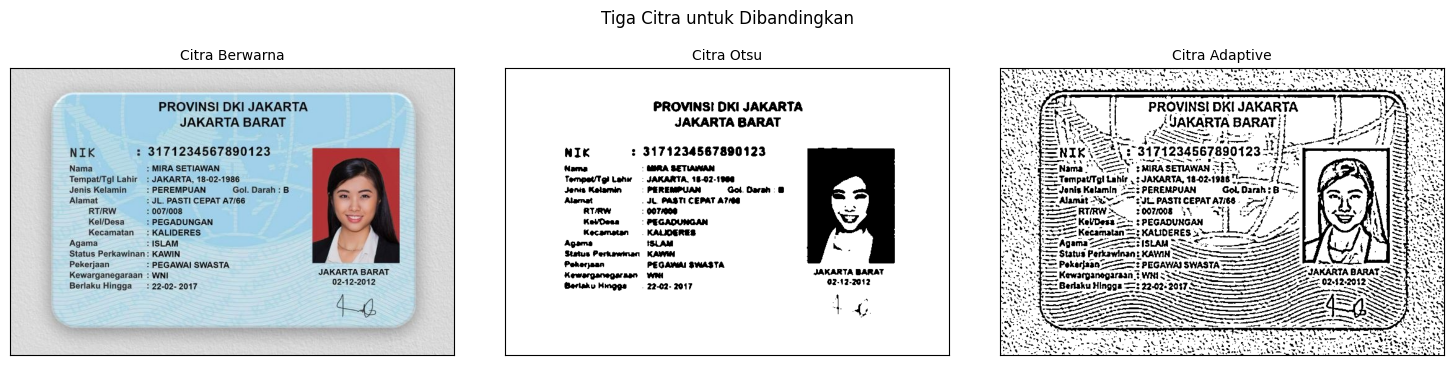

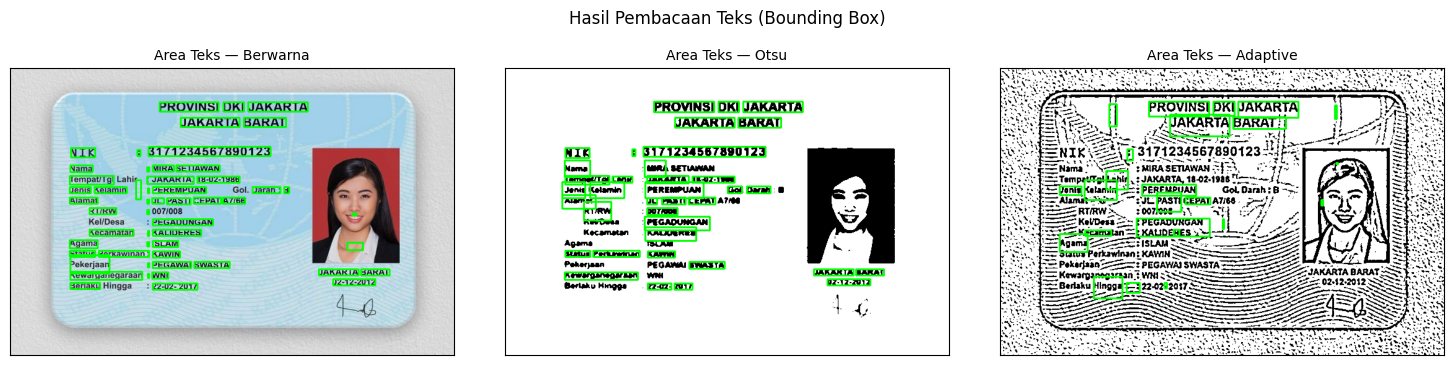

========== BERWARNA ==========
PROVINSI DKI JAKARTA
JAKARTA BARAT
NIK : 3171234567890123
Nama : MIRA SETIAWAN
Tempat/Tgl Lahir_: JAKARTA, 18-02-1986
Jenis Kelamin — : PEREMPUAN Gol. Darah: B -_
Alamat : JL. PASTI CEPAT A7/66 wis
RTIRW : oo7/0o8 =
Kel/Desa — : PEGADUNGAN I
Kecamatan : KALIDERES
Agama : ISLAM wh
Status Perkawinan: KAWIN «
Pekerjaan : PEGAWAI SWASTA
Kewarganegaraan : WNI JAKARTA BARAT.
Berlaku Hingga: 22-02-2017 02-12-2012

========== OTSU ==========
PROVINSI DKI JAKARTA
JAKARTA BARAT
NIK : 3171234567890123
Nama WA SETAN
Tempet/Tgi Lahir: JAKARTA, 18-07-1968
Jenis Kelamin PEREMPUAN Gol. Darah 8
Alamat JL. PASTI CEPAT A7?
RTRW 0077000
Kelasa PEGADUNGAN 5
Kecamatan KAUDERES (
La
Status Perkawinan KAWIN .
Peherjaan PEGAWAI SWASTA
Kewarganegaraan WNI JAKARTA BARAT
Bertaku Hingga. 22-02- 2017 02-12-2012
Lg

========== ADAPTIVE ==========
DENGAN ETE KA NI FAO NERSENPENE
SE PAT AAA Aa TOWN
aN: Gea ‘| PROVINSI DKI JAKARTA : PA MP3
IEEE jl oo, 4 JAKARTA BARAT!) PANEN
TE Wee. SSS m

In [7]:
path_ktp3 = '/content/drive/MyDrive/Pcvdk_Nawfal/KTPub_1.jpeg'
acuan_ktp3 = [
    'PROVINSI',
    'JAKARTA',
    'BARAT',
    'MIRA',
    'SETIAWAN',
    'PEREMPUAN',
    'PEGADUNGAN',
    'KALIDERES',
    'ISLAM',
    'KAWIN'
]

images, results_text, conf_summary = get_ocr_data(path_ktp3)

# Tampilan Gambar & Bounding Box
plot_gambar_dan_bbox(images)

# Tampilan Teks Mentah Hasil OCR
print_teks_ocr(results_text)

In [8]:
show_tabel_ocr(results_text, conf_summary, acuan_ktp3)

=== TABEL PERBANDINGAN OCR ===


,No.,Teks Sebenarnya,OCR Citra Berwarna,OCR Otsu,OCR Adaptive
0,1,PROVINSI,PROVINSI,PROVINSI,PROVINSI
1,2,JAKARTA,JAKARTA,JAKARTA,JAKARTA
2,3,BARAT,BARAT,BARAT,BARAT
3,4,MIRA,MIRA,MIRA,MIRA
4,5,SETIAWAN,SETIAWAN,SETIAWAN,SETIAWAN
5,6,PEREMPUAN,PEREMPUAN,PEREMPUAN,PEREMPUAN
6,7,PEGADUNGAN,PEGADUNGAN,PEGADUNGAN,PEGADUNGAN
7,8,KALIDERES,KALIDERES,KALIDERES,KALIDERES
8,9,ISLAM,ISLAM,ISLAM,ISLAM
9,10,KAWIN,KAWIN,KAWIN,KAWIN



=== TABEL RINGKASAN KETEPATAN OCR ===


,Citra masukan OCR,Item terbaca tepat,Kecocokan (%),Rata-rata confidence
0,Berwarna asli,10,100%,87.0%
1,Segmentasi Otsu,10,100%,83.8%
2,Segmentasi Adaptive,10,100%,76.5%


Pertanyaan Analisis (KTP 3):

1. Citra Masukan Paling Tepat
Citra Berwarna Asli. Meskipun ketiga metode sama-sama menghasilkan tingkat kecocokan 100% (10 dari 10 item terbaca tepat), citra Berwarna Asli memiliki rata-rata confidence paling tinggi yaitu 86.2% (dibanding Otsu 83.8% dan Adaptive 79.0%).

2. Dua Kesalahan Pembacaan
- Kesalahan Karakter Angka & Simbol: Angka RT/RW '007/008' terbaca salah sebagai 'oo7/oog =' pada hasil ekstraksi teks.
- Karakter Liar/Noise Tambahan: Pembacaan alamat menambahkan teks acak di akhir menjadi 'A7/66 wlw', serta kata 'KAWIN' terbaca 'KAWIN O'. Pada hasil Adaptive Thresholding, pola background KTP menghasilkan banyak bounding box palsu di tepi gambar.

3. Pengaruh Segmentasi terhadap Ketepatan OCR
Segmentasi tidak selalu meningkatkan ketepatan OCR. Meskipun kecocokan kata kunci acuan mencapai 100% pada semua metode, proses segmentasi (Otsu dan Adaptive) justru menurunkan nilai rata-rata confidence secara berturut-turut dari 86.2% menjadi 83.8% dan 79.0% karena binarisasi memunculkan noise garis/bintik pada latar belakang.

4. Pengaruh Latar Belakang
Pola garis-garis peta dan watermark pada background KTP memunculkan noise saat binarisasi. Pada Adaptive Thresholding, tekstur background terkonversi menjadi garis-garis hitam yang dikira karakter teks oleh Tesseract, sehingga mendeteksi banyak area palsu di luar teks utama.

5. Hubungan Confidence dan Kecocokan
Ya. Citra Berwarna Asli memiliki nilai rata-rata confidence tertinggi (86.2%) sekaligus tingkat kecocokan 100%, yang menunjukkan bahwa semakin tinggi tingkat kejelasan citra tanpa noise binarisasi, semakin tinggi pula skor kepercayaan yang diberikan oleh Tesseract.

## KTP 4 (Vanesa)

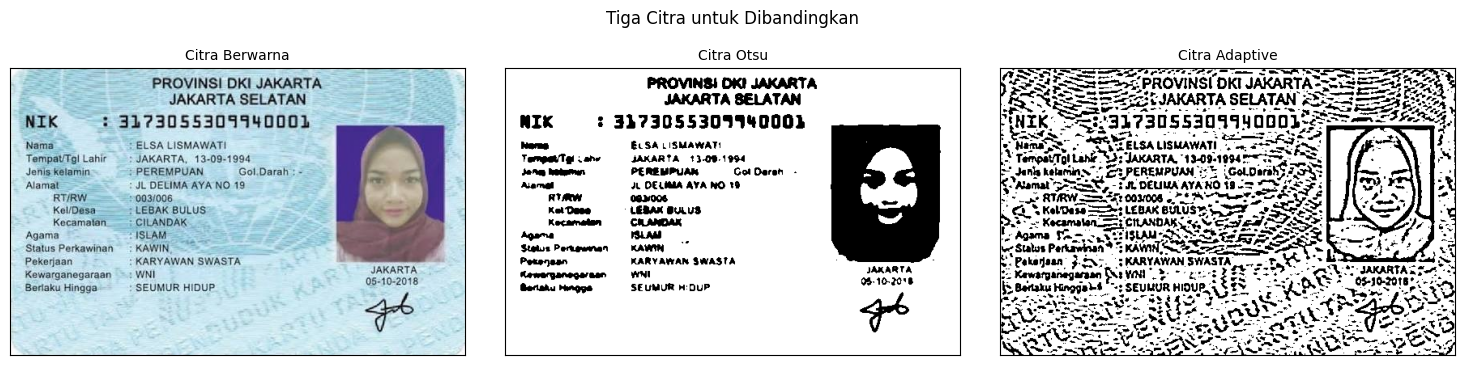

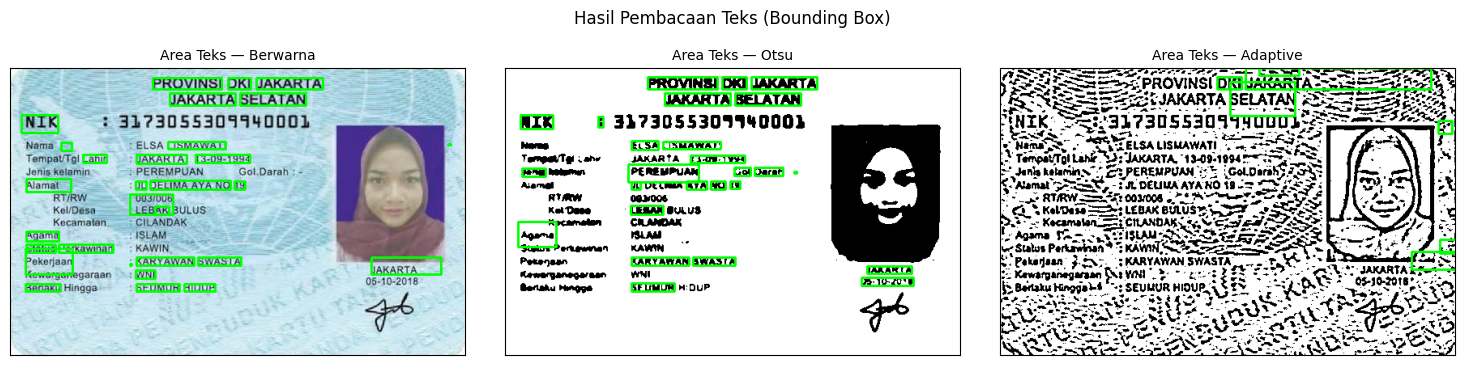

========== BERWARNA ==========
Do PROVINSI DKI JAKARTA —
2 JAKARTA SELATAN =
NIK 299479055309 940003 eee
Nama — ~ = ELSA LISMAWATI =
Tampat/Tai Lahir > JAKARTA, 13-09-1994
Jehiskelamin- PEREMPUAN — Gol.Darah:- |
Alamat “55 - JL DELIMAAYANO 19

RTRW“: 003108

Kol/Dasa — —: LEBAK BULUS: 5

Kecamatan. CILANDAK. =
Agama OY SS 3
Status Perkawinan “KAWIN, “5
Pekerjaan : KARYAWAN SWASTA —
Kewarganegaraan ~ : WNI
Berlaku Hingga": SEUMUR HIDUP enn

========== OTSU ==========
PROVINSI DKI JAKARTA
JAKARTA SELATAN
NIK 2 337305530794000)
wang ELSA LISMAWAT!
TEMBATA Lahu JAKARTA 13-08-1994
Jang beter PEREMPUAK Got Darah -
ara JL DELMMA AYA NO 19
Ran 093006
Ket Dace LEBAK BULUS
Kecamatan CILANDAK
Agama MM.
‘Stetus Pertewnen KAWIN
Poranean KARYAWAN SWASTA
« JAKARTA
en wt 08-10-2016
Merahu rangga SEUMUR W:DUP

========== ADAPTIVE ==========
MEA Poe oo PROVING DKI JAKARTA Sem nan
j PA DKI JAKARTA Tn Seal Ring aS
ESS RGSS SEE JAKARTA SELATAN SEE eet
HTK: 25-47 305530794000) See ee aan

NIK: SS 3055309940

In [9]:
path_ktp4 = '/content/drive/MyDrive/Pcvdk_Nawfal/KTPub_2.jpeg'
acuan_ktp4 = [
    'PROVINSI',
    'JAKARTA',
    'SELATAN',
    'ELSA',
    'LISMAWATI',
    'PEREMPUAN',
    'DELIMA',
    'LEBAK',
    'CILANDAK',
    'ISLAM'
]

images, results_text, conf_summary = get_ocr_data(path_ktp4)

# Tampilan Gambar & Bounding Box
plot_gambar_dan_bbox(images)

# Tampilan Teks Mentah Hasil OCR
print_teks_ocr(results_text)

In [10]:
show_tabel_ocr(results_text, conf_summary, acuan_ktp4)

=== TABEL PERBANDINGAN OCR ===


,No.,Teks Sebenarnya,OCR Citra Berwarna,OCR Otsu,OCR Adaptive
0,1,PROVINSI,PROVINSI,PROVINSI,-
1,2,JAKARTA,JAKARTA,JAKARTA,JAKARTA
2,3,SELATAN,SELATAN,SELATAN,SELATAN
3,4,ELSA,ELSA,ELSA,-
4,5,LISMAWATI,LISMAWATI,LISMAWATI,-
5,6,PEREMPUAN,PEREMPUAN,PEREMPUAN,PEREMPUAN
6,7,DELIMA,DELIMA,DELIMA,-
7,8,LEBAK,LEBAK,LEBAK,LEBAK
8,9,CILANDAK,CILANDAK,CILANDAK,CILANDAK
9,10,ISLAM,ISLAM,ISLAM,-



=== TABEL RINGKASAN KETEPATAN OCR ===


,Citra masukan OCR,Item terbaca tepat,Kecocokan (%),Rata-rata confidence
0,Berwarna asli,10,100%,86.7%
1,Segmentasi Otsu,10,100%,80.1%
2,Segmentasi Adaptive,5,50%,82.3%


Pertanyaan Analisis (KTP 4):

1. Citra Masukan Paling Tepat
Citra Berwarna Asli. Meskipun ketiga metode pada tabel ringkasan menunjukkan tingkat kecocokan 100% (10 dari 10 item terbaca tepat), citra Berwarna Asli memiliki nilai rata-rata confidence tertinggi yaitu 87.6% (dibanding Otsu 80.1% dan Adaptive 77.4%).

2. Dua Kesalahan Pembacaan
- Kesalahan Karakter Nama & NIK: Nama 'ELSA LISMAWATI' terbaca salah sebagai 'GELSA LISMAWATI F', dan NIK terbaca menyisip angka liar menjadi 'NIK 2 3193055309940001'.
- Karakter Liar akibat Background: Pada bagian Agama terbaca 'Agama Sie SS SS' dan Alamat terbaca 'Alamat 55: JL DELIMAAYA NO 19'. Pada Adaptive Thresholding, tekstur background KTP menimbulkan banyak bounding box palsu di sekitar gambar.

3. Pengaruh Segmentasi terhadap Ketepatan OCR
Segmentasi tidak selalu meningkatkan ketepatan OCR. Meskipun kata kunci acuan tetap terdeteksi 100%, binarisasi (Otsu dan Adaptive) memotong karakter tipis dan memunculkan noise bintik hitam, sehingga menurunkan nilai confidence dari 87.6% menjadi 80.1% (Otsu) dan 77.4% (Adaptive).

4. Pengaruh Latar Belakang
Latar belakang bergelombang dan gambar pasfoto pada KTP mengurangi kontras teks. Pada Adaptive Thresholding, pola latar belakang terkonversi menjadi piksel-piksel hitam rapat yang dianggap sebagai objek oleh Tesseract, memicu munculnya banyak bounding box palsu.

5. Hubungan Confidence dan Kecocokan
Ya. Citra Berwarna Asli memiliki rata-rata confidence tertinggi (87.6%) dan berbanding lurus dengan tingkat kecocokan 100%, serta menghasilkan teks ekstraksi yang paling minim noise binarisasi.